# 02 · Which hand? First model

From one movement to the nose, tell whether the right or the left hand made it.
This notebook builds the features, applies the analysis rules, tests the model on people it
has never seen (leave-one-subject-out) and compares a few simpler versions.

**How to run**

1. `pip install -r analysis/requirements.txt` (now includes scikit-learn).
2. Download the data: `python analysis/export_data.py` (needs `.env`, see notebook 01).
3. Run all cells. Outputs show people only in aggregate (D-35).

**Rules used** (`docs/decisions.md`): complete study sessions only (D-41); nobody excluded for how
they did the task (D-42); a trial is dropped only if its reach cannot be found (D-43); no speed
label or reaction time as features (D-44); acceleration + rotation rate, so only phones with a
gyroscope (D-48); participants under 18 included (D-49); only the reach, high beep → nose touch
(D-50); real rotation axes and signs (D-51); a reach in which the phone turned less than 4° in
total is "no movement" (D-52); logistic regression, leave-one-subject-out (D-15).

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "analysis" / "loading.py").exists())
sys.path.insert(0, str(ROOT / "analysis"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from loading import export_info, load_raw
from features import FEATURES, features_table, preprocess_trial, reach_end_ms
from model import (accuracy_table, coefficients, fit_final, leave_one_subject_out,
                   per_person_accuracy, select_study_trials, single_feature_rule)
from plots import HAND_COLORS, MUTED, TEXT_2, apply_style

apply_style()
pd.set_option("display.precision", 3)

raw_sessions, raw_trials = load_raw()
print("Export made:", export_info().get("exported_at", "?"))
print(f"{len(raw_sessions)} sessions, {len(raw_trials)} trials in the export")

Export made: 2026-11-14T16:43:32+00:00
41 sessions, 357 trials in the export


## 1. From raw samples to one row per reach

For every trial (`analysis/features.py`):

1. acceleration flipped for iPhone (D-28, D-36); rotation rate **not** flipped (D-51);
2. repeated readings removed (some Android browsers deliver the same reading twice), then the
   samples are put on an even **50 Hz** grid and smoothed with a 100 ms moving average (D-46);
3. the reach = from the high beep to the **first nose touch** (in the zone, or just outside it);
4. the features are computed over the reach.

Rotation columns get their real axes (D-51): `rot_x = gz`, `rot_y = gx`, `rot_z = gy`.

In [2]:
feats = features_table(raw_sessions, raw_trials)
data, left_out = select_study_trials(feats)

print(f"Used: {data['session_id'].nunique()} people, {len(data)} reaches")
left_out

Used: 22 people, 257 reaches


,reason,sessions,trials
0,pilot session,6,53
1,phone without gyroscope (D-48),2,24
2,reach not found (D-43),2,19
3,incomplete session (D-41),3,4


In [3]:
# Who is in the data (aggregate only)
people = data.drop_duplicates("session_id")
age = pd.to_numeric(people["age"], errors="coerce")
pd.DataFrame({"value": {
    "people": len(people),
    "right-handed / mixed / left-handed": " / ".join(
        str((people["handedness"] == g).sum()) for g in ["right-handed", "mixed", "left-handed"]),
    "under 18": int((age < 18).sum()),
    "Android / iPhone": f"{(people['platform'] == 'Android').sum()} / {(people['platform'] == 'iPhone').sum()}",
    "reaches: right hand / left hand": f"{(data['hand'] == 'right').sum()} / {(data['hand'] == 'left').sum()}",
}}).rename_axis("")

,value
,
people,22
right-handed / mixed / left-handed,16 / 1 / 5
under 18,5
Android / iPhone,12 / 10
reaches: right hand / left hand,126 / 131


### One reach, before and after preprocessing

Rotation about y (turning the phone about its long, vertical axis) of one right-hand reach:
raw samples (dots) and the even, smoothed grid (line).

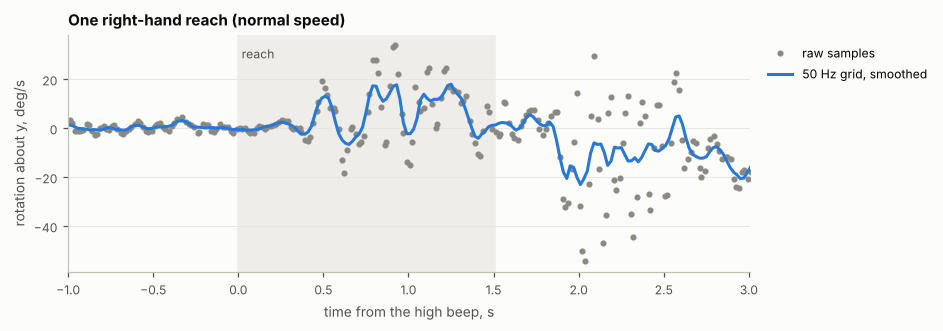

In [4]:
sessions_by_id = {s["id"]: s for s in raw_sessions}
example = next(t for t in raw_trials
               if t["id"] in set(data["trial_id"]) and t["hand"] == "right" and t["speed"] == "normal")
s = sessions_by_id[example["session_id"]]
platform = s["device"]["platform"]
grid = preprocess_trial(example, platform)
end, _ = reach_end_ms(example, s["device"]["zone"]["r_px"])
beep = example["t_beep_high_ms"]

raw_t = (np.array(example["samples"]["t"]) - beep) / 1000
raw_rot_y = np.array([np.nan if v is None else v for v in example["samples"]["gx"]], dtype=float)

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.plot(raw_t, raw_rot_y, "o", ms=3, color=MUTED, label="raw samples")
ax.plot((grid["t_ms"] - beep) / 1000, grid["rot_y"], color=HAND_COLORS["right"], lw=2,
        label="50 Hz grid, smoothed")
ax.axvspan(0, (end - beep) / 1000, color="#eeede9", zorder=0)
ax.text(0.02, 0.95, "reach", transform=ax.get_xaxis_transform(), color=TEXT_2, fontsize=8, va="top")
ax.set_xlim(-1, (end - beep) / 1000 + 1.5)
ax.set_xlabel("time from the high beep, s")
ax.set_ylabel("rotation about y, deg/s")
ax.set_title("One right-hand reach (normal speed)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

## 2. The features, and why these

A left-hand movement is roughly the **mirror image** of a right-hand one (mirror plane = the
person's midline, which reverses the phone's x axis). Acceleration is an ordinary vector, rotation
an axial one, so under the mirror only **acceleration x, rotation about y and rotation about z**
change sign. The features come from these three channels only:

| feature | meaning |
|---|---|
| `rot_y_angle` | net turn about y (the phone's long axis) over the reach, deg |
| `rot_y_max`, `rot_y_min` | largest rotation rate about y in each direction, deg/s |
| `rot_z_angle`, `rot_z_max`, `rot_z_min` | the same for the turn in the screen plane |
| `acc_x_mean`, `acc_x_max`, `acc_x_min` | sideways acceleration (with gravity) minus its value before the beep, m/s² |

In [5]:
data.groupby("hand")[FEATURES].mean().T.rename_axis("mean per hand")

hand,left,right
mean per hand,,
rot_y_angle,-8.051,8.343
rot_y_max,32.695,46.326
rot_y_min,-51.235,-30.536
rot_z_angle,0.659,0.664
rot_z_max,34.329,27.128
rot_z_min,-30.979,-26.963
acc_x_mean,0.078,0.009
acc_x_max,1.451,1.228
acc_x_min,-1.298,-1.207


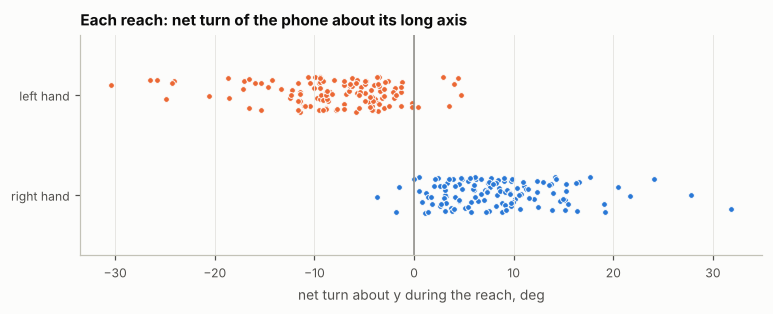

In [6]:
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(8, 2.6))
for i, hand in enumerate(["right", "left"]):
    x = data.loc[data["hand"] == hand, "rot_y_angle"]
    ax.scatter(x, i + rng.uniform(-0.18, 0.18, len(x)), s=14, color=HAND_COLORS[hand],
               edgecolor="#fcfcfb", linewidth=0.6)
ax.axvline(0, color=MUTED, lw=1)
ax.set_yticks([0, 1], ["right hand", "left hand"])
ax.set_ylim(-0.6, 1.6)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlabel("net turn about y during the reach, deg")
ax.set_title("Each reach: net turn of the phone about its long axis")
plt.show()

Per person: mean net turn of the right-hand and of the left-hand reaches (one line = one
person, sorted). A person whose two dots are on the same side of 0 turns the phone the same way
with both hands, and the model cannot separate their hands.

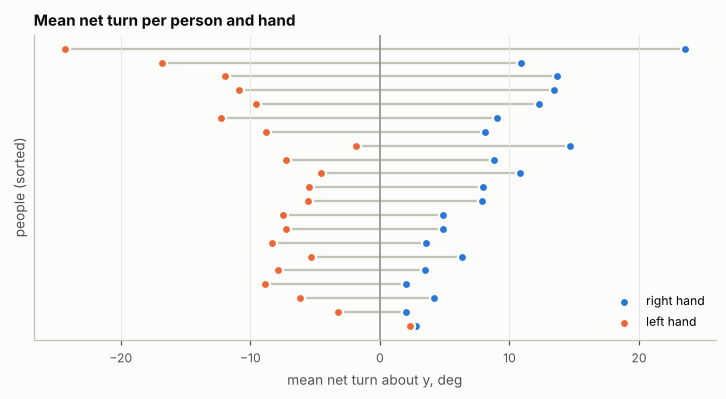

21 of 21 people: right-hand mean above left-hand mean; 20 with the two means on opposite sides of 0


In [7]:
per = data.pivot_table(index="session_id", columns="hand", values="rot_y_angle", aggfunc="mean")
per = per.dropna().assign(gap=lambda d: d["right"] - d["left"]).sort_values("gap").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8, 3.6))
for i, row in per.iterrows():
    ax.plot([row["left"], row["right"]], [i, i], color="#c3c2b7", lw=1.5, zorder=1)
for hand in ["right", "left"]:
    ax.scatter(per[hand], per.index, s=36, color=HAND_COLORS[hand], edgecolor="#fcfcfb",
               linewidth=1.5, zorder=2, label=f"{hand} hand")
ax.axvline(0, color=MUTED, lw=1)
ax.set_yticks([])
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlabel("mean net turn about y, deg")
ax.set_ylabel("people (sorted)")
ax.set_title("Mean net turn per person and hand")
ax.legend(loc="lower right")
plt.show()
print(f"{(per['right'] > per['left']).sum()} of {len(per)} people: right-hand mean above left-hand mean;"
      f" {((per['right'] > 0) & (per['left'] < 0)).sum()} with the two means on opposite sides of 0")

## 3. Test on people the model has not seen

Leave-one-subject-out: for each person, the model is trained on everybody else and predicts this
person's reaches. Model: standardised features → logistic regression (C = 1, fixed in advance).
The output is the probability of the left hand; the predicted hand is the more likely one, and its
probability is the confidence shown to the user.

In [8]:
res = leave_one_subject_out(data)
accuracy_table(res)

,people,trials,accuracy,mean_confidence
,,,,
all,22,257,0.942,0.912


In [9]:
pd.concat({by: accuracy_table(res, by) for by in ["handedness", "hand", "speed", "platform"]})

people  trials  accuracy  mean_confidence
handedness left-handed        5      53     1.000            0.937
           mixed              1      12     1.000            1.000
           right-handed      16     192     0.922            0.899
hand       left              22     131     0.931            0.917
           right             21     126     0.952            0.906
speed      fast              22      85     0.941            0.925
           normal            22      86     0.953            0.907
           slow              22      86     0.930            0.903
platform   Android           12     137     0.927            0.921
           iPhone            10     120     0.958            0.901

In [10]:
pp = per_person_accuracy(res)
print("Accuracy per person (anonymous, sorted):")
print(pp["accuracy"].round(2).tolist())
print(f"{(pp['accuracy'] == 1).sum()} of {len(pp)} people: all reaches correct")
print(f"Mean confidence when right: {res.loc[res['correct'], 'confidence'].mean():.2f}, "
      f"when wrong: {res.loc[~res['correct'], 'confidence'].mean():.2f}")

Accuracy per person (anonymous, sorted):
[0.42, 0.83, 0.92, 0.92, 0.92, 0.92, 0.92, 0.92, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
14 of 22 people: all reaches correct
Mean confidence when right: 0.92, when wrong: 0.70


## 4. Simpler versions

Model A (above) uses the 9 features chosen before training. B and C use only the rotation about y;
the "sign rule" has no training at all: left hand if the net turn about y is negative (the
direction is taken from the other people). Same leave-one-subject-out test.

These versions were compared **after** seeing the result of A, so their numbers are slightly
optimistic; with 22 people a difference of a few reaches is within noise.

In [11]:
variants = {
    "A: all 9 features": FEATURES,
    "B: rotation about y (3)": ["rot_y_angle", "rot_y_max", "rot_y_min"],
    "C: net turn about y only": ["rot_y_angle"],
}
rows = {}
for name, fs in variants.items():
    r = leave_one_subject_out(data, fs)
    acc_pp = r.groupby("session_id")["correct"].mean()
    rows[name] = {"features": len(fs), "correct": f"{r['correct'].sum()} / {len(r)}",
                  "accuracy": r["correct"].mean(), "people all correct": f"{(acc_pp == 1).sum()} / {len(acc_pp)}",
                  "worst person": acc_pp.min()}
r = single_feature_rule(data, "rot_y_angle")
acc_pp = r.groupby("session_id")["correct"].mean()
rows["sign rule (no training)"] = {"features": 1, "correct": f"{r['correct'].sum()} / {len(r)}",
                                   "accuracy": r["correct"].mean(),
                                   "people all correct": f"{(acc_pp == 1).sum()} / {len(acc_pp)}",
                                   "worst person": acc_pp.min()}
pd.DataFrame(rows).T

,features,correct,accuracy,people all correct,worst person
A: all 9 features,9,242 / 257,0.942,14 / 22,0.417
B: rotation about y (3),3,247 / 257,0.961,18 / 22,0.417
C: net turn about y only,1,246 / 257,0.957,17 / 22,0.417
sign rule (no training),1,247 / 257,0.961,18 / 22,0.417


## 5. Extra check: the pilot sessions

The pilot sessions are never used for training (D-32), but they are a useful extra test: two of them
are Masha's own runs on the **S24 Ultra**, the phone of the final test, and one is Prof. Bar-Gad
trying the app on the same phone (4 right-hand reaches). The pilots used an older protocol (speeds
not in pairs, app before 2.2.0). The one-trial restart of a study participant is left out, because
that person is in the training data.

In [12]:
groups = {
    "B34CF91D": "Masha, S24 Ultra", "8DA2C63C": "Masha, S24 Ultra",
    "048CA3F5": "Prof. Bar-Gad, S24 Ultra",
    "F50F9F36": "iPhone pilots", "A56549CD": "iPhone pilots",
}
pilots = feats[feats["code"].isin(groups) & feats["excluded"].isna()].copy()
pilots["group"] = pilots["code"].map(groups)
out = {}
for name, fs in variants.items():
    p = fit_final(data, fs).predict_proba(pilots[fs])[:, 1]
    ok = np.where(p >= 0.5, "left", "right") == pilots["hand"]
    out[name] = pilots.assign(ok=ok).groupby("group")["ok"].agg(lambda s: f"{s.sum()} / {len(s)}")
pd.DataFrame(out)

,A: all 9 features,B: rotation about y (3),C: net turn about y only
group,,,
"Masha, S24 Ultra",24 / 24,24 / 24,24 / 24
"Prof. Bar-Gad, S24 Ultra",3 / 4,4 / 4,4 / 4
iPhone pilots,23 / 24,24 / 24,24 / 24


## 6. The trained model A

Weights on the standardised features (trained on all used people): positive pushes towards the
left hand, negative towards the right.

In [13]:
coefficients(fit_final(data)).round(2)

,weight
feature,
rot_y_angle,-4.68
rot_y_max,0.28
rot_y_min,-0.22
rot_z_angle,0.60
rot_z_max,-0.44
rot_z_min,-0.50
acc_x_mean,0.30
acc_x_max,0.38
acc_x_min,0.20


## Notes

- Almost all of the information is in one number: the **net turn of the phone about its long axis**
  during the reach. It is opposite for the two hands in most people; the accelerometer cannot see
  it (D-51), which is why the gyroscope matters.
- Errors concentrate in a few people. In the worst one, the left hand turned the phone the same
  way as the right hand. More people (especially more left-handed) would show how common this is.
- Not checked yet: the way back (D-50), a learning curve (accuracy vs number of training people),
  and the same computation in the browser for the test mode.